# Persist, Fade, or See Through It? Audience Responses to a Repeated Sexualised Ad Tactic


**Overarching question.** When the same controversial marketing tactic (here, the sexualised portrayal of a female endorser) is repeated, did audience attitudes toward it change, and if so, how?

**Comparison.** American Eagle (AE) *"Sydney Sweeney Has Great Jeans"* (launched 23 Jul 2025) vs Novig *"Just sports"* (launched 9 Sep 2026). Same endorser, similar tactic; both brands kept working with her. Only **gender-related** comments are compared, because the sexualised portrayal is the one controversy the two ads share.

**Research questions.**
- **RQ1 (persistence):** Did criticism of the sexualised portrayal persist from the AE to the Novig campaign, and over time within each?
- **RQ2 (form):** Did the form of criticism change, toward indifference (T2) or toward recognising the marketing tactic (T3)?
- **RQ3 (focus):** What did the discussion focus on, and did that focus change between the two campaigns?

**Three competing scenarios (Framework T).**

| Level of attitude | T1 Persistence | T2 Desensitisation | T3 Persuasion knowledge | RQ |
|---|---|---|---|---|
| Tone: negative share and emotional intensity | same | lower | lower | RQ1 |
| Stance: share objecting to the portrayal | same or higher | lower | about the same | RQ1 |
| Form of criticism | mainly moral condemnation | growing indifference | growing references to the marketing tactic | RQ2 |

**Data.** Top-level YouTube comments collected with the YouTube Data API v3 (see `sydeney data collection.py`). Conclusions are stated at the level of public discourse, not individual users.

In [ ]:
# Install libraries 
%pip install -q textblob vaderSentiment wordcloud gensim pyLDAvis langdetect emoji

Note: you may need to restart the kernel to use updated packages.


In [3]:
# ---- Standard library ----
import re, random, warnings
from collections import Counter

# ---- Data handling and plotting ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Text preprocessing (NLTK) ----
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# ---- Analysis libraries ----
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy import stats
from langdetect import detect, DetectorFactory, LangDetectException
import emoji
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel

warnings.filterwarnings('ignore')        # hide library deprecation warnings (they do not affect results)
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(pkg, quiet=True)       # download the NLTK resources used below (tokeniser, stopwords, WordNet)

SEED = 42                      # one seed for every random step -> reproducible results
random.seed(SEED); np.random.seed(SEED)
DetectorFactory.seed = 0       # makes langdetect deterministic

pd.set_option('display.max_colwidth', 120)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
COLORS = {'AE': '#1f4e79', 'Novig': '#c55a11'}   # one colour per campaign, used in every chart

import os
os.makedirs('figures', exist_ok=True)            # figures for the report are saved here

## Part 1. Python Refresher and Setup

### 1.1 Loop and control flow
For each sentence: print it, count its words with `.split()`, and check (case-insensitively) whether it mentions Python.

In [4]:
# A list of example sentences (the last two are related to this project)
sentences = [
    "I love data.",
    "Python is fun!",
    "NUS rocks!",
    "Sydney Sweeney has great jeans, apparently.",
    "I analysed the comments with PYTHON and pandas.",
]

for sentence in sentences:                       # loop over every sentence in the list
    print(sentence)
    n_words = len(sentence.split())              # .split() breaks the sentence on whitespace
    print(f"  Number of words: {n_words}")
    if "python" in sentence.lower():             # lower-case first, so 'Python' and 'PYTHON' both match
        print("  -> This sentence mentions Python.")
    else:
        print("  -> No mention of Python.")

I love data.
  Number of words: 3
  -> No mention of Python.
Python is fun!
  Number of words: 3
  -> This sentence mentions Python.
NUS rocks!
  Number of words: 2
  -> No mention of Python.
Sydney Sweeney has great jeans, apparently.
  Number of words: 6
  -> No mention of Python.
I analysed the comments with PYTHON and pandas.
  Number of words: 8
  -> This sentence mentions Python.


### 1.2 Function: extract hashtags and mentions

In [5]:
def extract_entities(text):
    '''Return a list of hashtags (#...) and mentions (@...) found in a string.

    Uses a regular expression: '#' or '@' followed by one or more word characters.
    Returns an empty list for empty or missing input.
    '''
    if not isinstance(text, str) or text == "":   # guard against empty or non-string input
        return []
    # Pattern: '#' + word characters  OR  '@' + word characters; findall returns every match as a list
    return re.findall(r"#\w+|@\w+", text)

# Quick tests, including edge cases
print(extract_entities("I love #AI and @OpenSource!"))        # ['#AI', '@OpenSource']
print(extract_entities("#SydneySweeney ad by @AmericanEagle #ad #ad"))  # duplicates are kept
print(extract_entities(""))                                    # []
print(extract_entities("no tags here"))                        # []

['#AI', '@OpenSource']
['#SydneySweeney', '@AmericanEagle', '#ad', '#ad']
[]
[]


These helper patterns (loops, conditionals, functions with docstrings and tests) are reused in Parts 3–4: `clean_text()`, `preprocess()`, `lexicon_share()` and `label_sentiment()` are all custom functions.

## Part 2. Data Familiarisation and Preparation

### 2.1 Load and inspect
`sweeney_comments_all.csv` holds every top-level comment collected from 61 videos (29 AE, 32 Novig), from each campaign's launch to the collection date.

In [6]:
# ---- Step 1: load the raw data ----
DATA_PATH = 'sweeney_comments_all.csv'   # upload this file to Colab first
raw = pd.read_csv(DATA_PATH)             # load every collected comment into a DataFrame
raw['published_at'] = pd.to_datetime(raw['published_at'], utc=True)   # text -> real timestamps (UTC) so dates can be compared

raw.head()

,comment_id,source_id,author,text,published_at,like_count,campaign,source_type,days_since_launch
0,UgxR1xU5YCVQUvLfZa54AaABAg,AK8s3iqL99c,@franciscojavierjimenezdiaz5236,"Todos se le lanzaron a la yugular a Sydney Sweney por este anuncio, como si la culpa no hubiese sido de quien lo esc...",2026-10-25 17:12:58+00:00,0,AE,ad,459
1,UgwfXGqxDlpCPaDKj214AaABAg,AK8s3iqL99c,@aresthecommenter1424,Love this,2026-10-23 10:27:16+00:00,0,AE,ad,457
2,Ugwf2ZHVefVN2pVumKd4AaABAg,AK8s3iqL99c,@JillJillMeowUSA,"Is this the new reversed advertisment strategy? Like I'm not here to promote a special girl JillJillmeow, but She is...",2026-10-22 08:44:47+00:00,0,AE,ad,456
3,UgwKIYtViAM1gYyqTLJ4AaABAg,AK8s3iqL99c,@HamedKebe-t7h,Baby move to the green your best side😂,2026-10-15 23:02:56+00:00,0,AE,ad,449
4,UgyBZ041yHVcsFbq7x54AaABAg,AK8s3iqL99c,@thesherrifisnear,The new Sharon Marie Tate,2026-10-14 00:52:25+00:00,0,AE,ad,448


In [7]:
# Column names, data types and non-missing counts for each column
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88628 entries, 0 to 88627
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   comment_id         88628 non-null  object             
 1   source_id          88628 non-null  object             
 2   author             88627 non-null  object             
 3   text               88607 non-null  object             
 4   published_at       88628 non-null  datetime64[ns, UTC]
 5   like_count         88628 non-null  int64              
 6   campaign           88628 non-null  object             
 7   source_type        88628 non-null  object             
 8   days_since_launch  88628 non-null  int64              
dtypes: datetime64[ns, UTC](1), int64(2), object(6)
memory usage: 6.1+ MB


In [8]:
# Summary statistics of the numeric columns (e.g. like_count, reply_count, days_since_launch)
raw.describe()

,like_count,days_since_launch
count,88628.000000,88628.000000
mean,16.763630,21.200524
std,381.694436,47.438754
min,0.000000,0.000000
25%,0.000000,7.000000
50%,0.000000,10.000000
75%,1.000000,15.000000
max,54557.000000,459.000000


**Key columns.**

| Role | Column |
|---|---|
| User | `author` |
| Time | `published_at`, `days_since_launch` |
| Text | `text` |
| Engagement | `like_count` |
| Grouping | `campaign`, `source_type` (ad / news / commentary / creator / entertainment), `source_id` (video) |

### 2.2 Missing values and duplicates

In [9]:
# Count missing values in each column (isnull() marks missing cells as True; sum() counts them)
print("Missing values per column:\n", raw.isnull().sum(), sep='')
print("\nDuplicated rows (all columns):", raw.duplicated().sum())          # rows identical in every column
print("Duplicated comment IDs:", raw['comment_id'].duplicated().sum())    # the same comment collected twice
print("Same author posting identical text:", raw.duplicated(subset=['author', 'text']).sum())  # repeated posts

Missing values per column:
comment_id            0
source_id             0
author                1
text                 21
published_at          0
like_count            0
campaign              0
source_type           0
days_since_launch     0
dtype: int64

Duplicated rows (all columns): 6
Duplicated comment IDs: 6
Same author posting identical text: 559


In [10]:
# ---- Step 2: clean - remove duplicates and empty comments ----
n0 = len(raw)
df = raw.drop_duplicates(subset='comment_id')               # API pagination occasionally returns a comment twice
df = df.dropna(subset=['text'])                             # comments with no text cannot be analysed
df = df.drop_duplicates(subset=['author', 'text'])          # same person posting the same text = spam/repeat
# Identical text from DIFFERENT people (e.g. 'lol') is kept: it is genuine, independent reaction.
print(f"Rows before: {n0:,}  after cleaning: {len(df):,}  removed: {n0 - len(df):,}")

Rows before: 88,628  after cleaning: 88,049  removed: 579


### 2.3 Build the two analysis datasets

- **Main dataset** (AE vs Novig): comments posted within **45 days of each campaign's launch** (equal windows), at most **500 comments per video** (random sample) so no single video dominates.
- **AE longitudinal dataset**: all AE comments from launch to today, no sampling (used in Part 4.6).

In [11]:
# ---- Step 3: build the main dataset (45-day window, max 500 comments per video) and the AE long-term dataset ----
WINDOW_DAYS, CAP = 45, 500     # 45-day window after each launch; at most 500 comments per video

# Keep comments posted on days 0-44 after their campaign's launch (same length for both campaigns)
in_window = df[df['days_since_launch'].between(0, WINDOW_DAYS - 1)]
main = (in_window.sample(frac=1, random_state=SEED)   # shuffle, then keep the first 500 per video
                 .groupby('source_id').head(CAP)      # the cap stops one viral video from dominating the sample
                 .reset_index(drop=True))             # renumber rows 0, 1, 2, ...
ae_long = df[df['campaign'] == 'AE'].copy()           # every AE comment, no window: used for the long-term analysis (4.6)

print("Main dataset:", main.shape, "| AE longitudinal:", ae_long.shape)   # shape = (rows, columns)

Main dataset: (20208, 9) | AE longitudinal: (61650, 9)


### 2.4 Descriptive summaries

In [11]:
# One row per campaign: size of the data, date range and engagement
summary = main.groupby('campaign').agg(
    comments=('comment_id', 'size'),
    videos=('source_id', 'nunique'),
    first=('published_at', 'min'),
    last=('published_at', 'max'),
    median_likes=('like_count', 'median'),
    mean_likes=('like_count', 'mean'),
)
summary

,comments,videos,first,last,median_likes,mean_likes
campaign,,,,,,
AE,12034,29,2025-07-23 16:22:21+00:00,2025-09-05 22:54:14+00:00,0.0,20.419063
Novig,8174,31,2026-09-09 13:49:42+00:00,2026-10-23 21:25:45+00:00,0.0,25.113041


In [12]:
# Source composition: how many comments come from each type of video
composition = pd.crosstab(main['source_type'], main['campaign'], margins=True)
composition_pct = pd.crosstab(main['source_type'], main['campaign'], normalize='columns').round(3) * 100
display(composition); display(composition_pct.rename(columns=lambda c: f"{c} (%)"))

campaign,AE,Novig,All
source_type,,,
ad,3404,2489,5893
commentary,1000,1319,2319
creator,2058,2539,4597
entertainment,1500,357,1857
news,4072,1470,5542
All,12034,8174,20208


campaign,AE (%),Novig (%)
source_type,,
ad,28.3,30.5
commentary,8.3,16.1
creator,17.1,31.1
entertainment,12.5,4.4
news,33.8,18.0


In [13]:
# Top 5 most active users per campaign, anonymised (real usernames are not shown in the report)
for camp, g in main.groupby('campaign'):
    top = g['author'].value_counts().head(5)             # the 5 authors with the most comments
    anon = pd.DataFrame({'user': [f'{camp}_User_{chr(65+i)}' for i in range(len(top))],   # chr(65) = 'A', so User_A, User_B...
                         'comments': top.values})
    print(camp); display(anon)

AE


,user,comments
0,AE_User_A,16
1,AE_User_B,12
2,AE_User_C,9
3,AE_User_D,8
4,AE_User_E,6


Novig


,user,comments
0,Novig_User_A,19
1,Novig_User_B,13
2,Novig_User_C,12
3,Novig_User_D,10
4,Novig_User_E,9


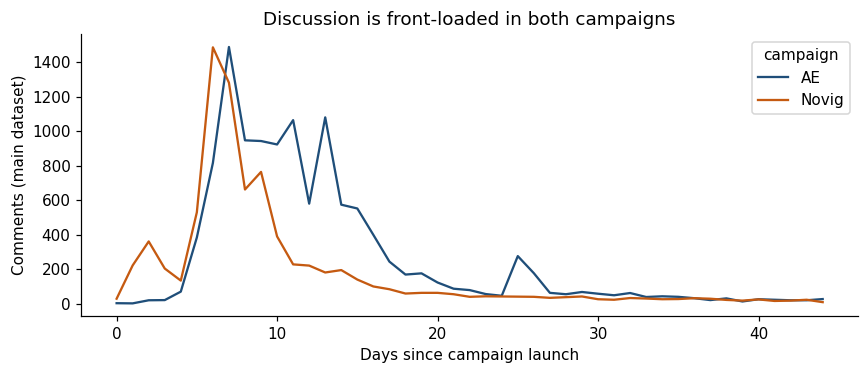

Share of comments posted in the first 7 days:
campaign
AE       0.110
Novig    0.364
Name: first_week, dtype: float64


In [14]:
# Daily comment volume after launch (descriptive only: volume also depends on the platform's algorithm)
daily = main.groupby(['campaign', 'days_since_launch']).size().unstack(0).fillna(0)
ax = daily.plot(color=[COLORS[c] for c in daily.columns], figsize=(8, 3.5))
ax.set(xlabel='Days since campaign launch', ylabel='Comments (main dataset)',
       title='Discussion is front-loaded in both campaigns')
plt.tight_layout(); plt.show()

print("Share of comments posted in the first 7 days:")
# first_week is True/False; the mean of True/False values = the share that is True
print(main.assign(first_week=main['days_since_launch'] < 7).groupby('campaign')['first_week'].mean().round(3))

In [15]:
# Engagement is highly skewed: a few comments receive most likes
print(main.groupby('campaign')['like_count'].describe(percentiles=[.5, .9, .99]).round(1))   # median, 90th and 99th percentiles
words = main['text'].str.split().str.len()
print("\nWords per comment:\n", words.groupby(main['campaign']).describe().round(1))

            count  mean    std  min  50%  90%    99%      max
campaign                                                     
AE        12034.0  20.4  254.7  0.0  0.0  5.0  299.7  14883.0
Novig      8174.0  25.1  310.4  0.0  0.0  8.0  364.8  12051.0

Words per comment:
             count  mean   std  min  25%   50%   75%    max
campaign                                                  
AE        12034.0  17.9  23.8  1.0  6.0  11.0  21.0  626.0
Novig      8174.0  19.7  31.0  1.0  6.0  12.0  22.0  744.0


### 2.5 Observations
- **Volume.** 88,628 top-level comments were collected; 579 were removed (6 duplicated IDs, 21 empty, and repeated identical posts by the same author). The main dataset contains **12,034 AE** comments from 29 videos and **8,174 Novig** comments from 31 videos.
- **Engagement is extremely skewed.** The median comment receives 0 likes while a handful receive over 10,000, so medians rather than means should be reported for likes.
- **Comments are short** (median 11–12 words). This limits LDA, so only comments with at least 3 tokens are used for topic modelling.
- **The source mix differs.** AE comments come more from news videos (34% vs 18%), Novig comments more from individual creators (31% vs 17%). Results are therefore also compared within the same source type (Part 4.4).
- **Timing differs.** 36% of Novig comments arrive in the first week, compared with 11% for AE, whose controversy only peaked in week 2 (news coverage and the 4 August Trump post). Weekly comparisons are aligned on days since launch.

## Part 3. Data Cleaning and Keyword Analysis

### 3.1 Language filter
All tools used later (TextBlob, VADER, NLTK) are built for English, so non-English comments are removed. Very short comments (fewer than 3 words) are kept without testing, because language detection is unreliable on them.

In [16]:
def is_english(text):
    '''Return True if langdetect judges the text to be English (short texts are kept).'''
    letters_only = re.sub(r'[^A-Za-z\s]', ' ', str(text))   # keep only Latin letters and spaces
    if len(letters_only.split()) < 3:                        # fewer than 3 words: too short to detect reliably
        return True                                          # -> keep it rather than drop it by mistake
    try:
        return detect(str(text)) == 'en'                     # True only if the detected language is English
    except LangDetectException:                              # langdetect fails on some texts (e.g. only symbols)
        return True                                          # -> keep them; emoji-only comments are handled later

main['is_english'] = main['text'].apply(is_english)
print(main.groupby('campaign')['is_english'].mean().round(3))
main = main[main['is_english']].reset_index(drop=True)       # keep English comments only (the tools below are English-only)
print("Main dataset after language filter:", len(main))

campaign
AE       0.925
Novig    0.945
Name: is_english, dtype: float64
Main dataset after language filter: 18855


### 3.2 Two text columns

- `text` (original) is kept for **sentiment analysis**: TextBlob and VADER use punctuation, capitals and negations.
- `clean_text` and `tokens` are used for **keywords, TF–IDF and topic modelling**.

In [17]:
# ---- Step 1: clean_text() - prepares text for word counts and topic modelling ----
URL_RE = re.compile(r'http\S+|www\.\S+')     # matches links
MENTION_RE = re.compile(r'@\w+')              # matches @username

def clean_text(text):
    '''Lower-case; remove URLs, @mentions, emojis/symbols, digits and punctuation; squeeze spaces.'''
    text = str(text).lower()                     # 'GREAT' and 'great' become the same word
    text = URL_RE.sub(' ', text)
    text = MENTION_RE.sub(' ', text)
    text = text.replace("'", "")                 # "don't" -> "dont" (kept as one token)
    text = re.sub(r'[^a-z\s]', ' ', text)        # keeps letters only: drops emojis, symbols, digits
    return re.sub(r'\s+', ' ', text).strip()

# Two text columns: 'text' (original, WITH emojis, used for sentiment) and 'clean_text' (for word counts and topics)
main['clean_text'] = main['text'].apply(clean_text)
main['has_letters'] = main['clean_text'].str.len() > 0   # False = emoji/symbol-only comment
print("Emoji/symbol-only comments (excluded from sentiment):")
print(main.groupby('campaign')['has_letters'].apply(lambda s: (~s).sum()))   # ~ flips True/False, so this counts the False ones

print(clean_text("Check this out https://t.co/x @AmericanEagle she's GREAT!!! 🔥🔥 #jeans"))

Emoji/symbol-only comments (excluded from sentiment):
campaign
AE       206
Novig    144
Name: has_letters, dtype: int64
check this out shes great jeans


In [18]:
# ---- Step 2: tokenise, lemmatise and remove stopwords ----
lemmatizer = WordNetLemmatizer()
STOP = set(stopwords.words('english'))
CUSTOM_STOP = {   # campaign names and filler words that would dominate every count
    'sydney', 'sweeney', 'syd', 'sweeneys', 'novig', 'american', 'eagle', 'ae', 'ad', 'ads', 'commercial',
    'amp', 'lol', 'lmao', 'like', 'get', 'got', 'one', 'would', 'also', 'even', 'really', 'im', 'dont',
    'thats', 'u', 'ur', 'oh', 'yeah', 'gonna', 'go', 'know', 'say', 'said', 'see', 'think', 'thing',
    'way', 'much', 'make', 'made', 'look', 'want', 'need', 'cant', 'didnt', 'doesnt', 'isnt', 'youre',
}
STOP |= CUSTOM_STOP

def preprocess(text):
    '''Tokenise cleaned text, lemmatise, and drop stopwords and 1–2 letter tokens.'''
    tokens = word_tokenize(text)                                    # sentence -> list of words
    tokens = [lemmatizer.lemmatize(t) for t in tokens]              # 'women' -> 'woman', 'bodies' -> 'body'
    return [t for t in tokens if t not in STOP and len(t) > 2]      # keep meaningful words only

main['tokens'] = main['clean_text'].apply(preprocess)
main[['text', 'tokens']].head(5)

,text,tokens
0,"True beauty is how one lives, thinks, and radiates from within.","[true, beauty, life, radiates, within]"
1,Looks like its time i shop at American Eagle.,"[time, shop]"
2,"If youtube have to forced me this vid as ads, i dont mind watching it full everytime. 😅😂","[youtube, forced, vid, mind, watching, full, everytime]"
3,"I think the saying goes ""they hate you cause they ain't you"". Respect for sticking up for yourself. They feel powerf...","[saying, hate, cause, aint, respect, sticking, feel, powerful, coerce, someone, appologize, nothing]"
4,It's good the proceeds from the jeans will be donated to mental health because Americans are for sure experiencing s...,"[good, proceeds, jean, donated, mental, health, sure, experiencing, sort, mental, break]"


### 3.3 Word frequencies and word clouds (all comments)

In [19]:
# ---- Top 20 words per campaign ----
top_words = {}
for camp, g in main.groupby('campaign'):
    counts = Counter(t for toks in g['tokens'] for t in toks)      # flatten all token lists and count each word
    top_words[camp] = counts.most_common(20)                       # the 20 most frequent words, as (word, count) pairs

# Put the two top-20 lists side by side in one table
freq_table = pd.DataFrame({
    f'{c} word': [w for w, _ in top_words[c]] for c in top_words
} | {
    f'{c} count': [n for _, n in top_words[c]] for c in top_words
})[['AE word', 'AE count', 'Novig word', 'Novig count']]
freq_table

,AE word,AE count,Novig word,Novig count
0,jean,2352,woman,2059
1,people,1916,sport,1355
2,gene,1352,people,793
3,great,1118,men,593
4,white,879,athlete,490
5,woman,816,body,432
6,good,695,shes,430
7,blue,631,gambling,375
8,woke,511,female,365
9,beautiful,508,love,329


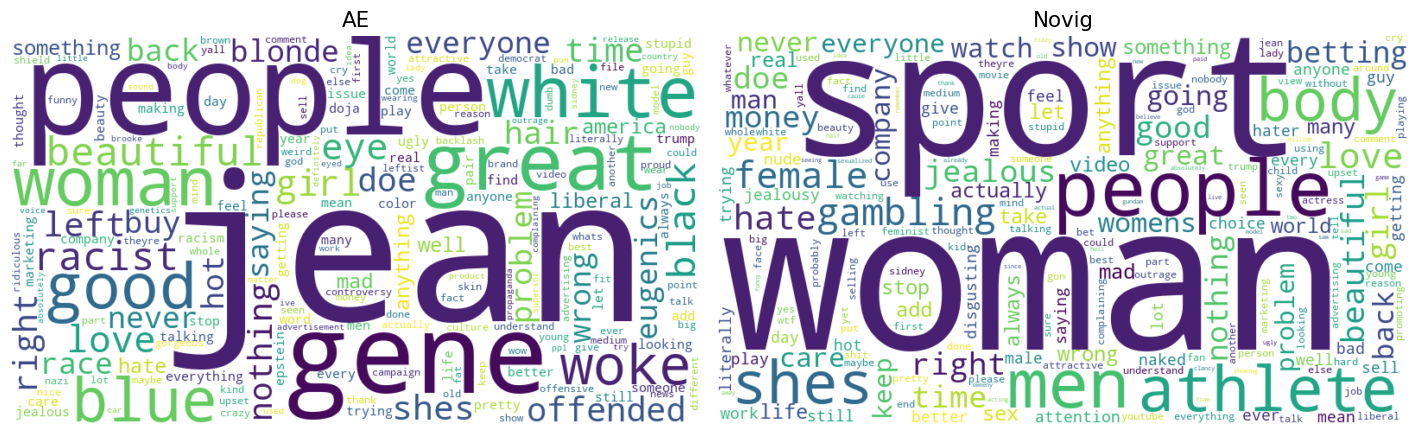

In [20]:
# ---- Word clouds: one per campaign ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (camp, g) in zip(axes, main.groupby('campaign')):
    counts = Counter(t for toks in g['tokens'] for t in toks)
    wc = WordCloud(width=800, height=450, background_color='white', colormap='viridis',
                   random_state=SEED).generate_from_frequencies(counts)   # bigger word = more frequent
    ax.imshow(wc, interpolation='bilinear'); ax.axis('off'); ax.set_title(camp, fontsize=14)
plt.tight_layout(); plt.savefig('figures/wordclouds.png', bbox_inches='tight'); plt.show()   # save for the appendix

### 3.4 TF–IDF: which terms distinguish each campaign?
TF–IDF is computed per comment (unigrams and bigrams, terms appearing in at least 5 comments), then averaged within each campaign. The *distinctiveness* score is the difference between the two campaign averages.

In [21]:
# ---- TF-IDF: which words and phrases are most typical of each campaign? ----
docs = main['tokens'].str.join(' ')            # token lists -> one string per comment (TfidfVectorizer needs strings)
# TF-IDF: words frequent in a comment but rare overall get high weight.
# ngram_range=(1, 2) = single words and two-word phrases; min_df=5 = in at least 5 comments; max_df=0.5 = in at most half
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.5)
X = tfidf.fit_transform(docs)
terms = np.array(tfidf.get_feature_names_out())

# Average TF-IDF weight of every term within each campaign
mean_by_camp = {c: np.asarray(X[(main['campaign'] == c).values].mean(axis=0)).ravel()
                for c in ['AE', 'Novig']}
tfidf_df = pd.DataFrame({'term': terms, 'AE': mean_by_camp['AE'], 'Novig': mean_by_camp['Novig']})
tfidf_df['diff'] = tfidf_df['AE'] - tfidf_df['Novig']      # positive = more typical of AE; negative = more typical of Novig

distinct = pd.DataFrame({
    'AE-distinctive': tfidf_df.nlargest(15, 'diff')['term'].values,      # 15 terms with the largest positive difference
    'Novig-distinctive': tfidf_df.nsmallest(15, 'diff')['term'].values,  # 15 terms with the largest negative difference
})
distinct

,AE-distinctive,Novig-distinctive
0,jean,sport
1,gene,woman
2,great,athlete
3,people,men
4,white,gambling
5,racist,body
6,woke,female
7,blue,betting
8,great jean,woman sport
9,black,disgusting


### 3.5 Gender-related subset
Comments are selected using **neutral topical words only** (no evaluative words such as *objectify*), otherwise the subset would contain only criticism by construction. *man* is excluded because it is often used as an interjection ("man, this is crazy"); *athlete* is excluded because it only applies to Novig.

In [22]:
# Neutral topic words (not evaluative), so the subset is not biased toward criticism or praise.
# 'man' is excluded because it is mostly used as an exclamation ('oh man').
GENDER_TERMS = ['women', 'woman', 'female', 'females', 'girl', 'girls', 'men', 'male', 'males',
                'body', 'bodies', 'gender', 'feminist', 'feminists', 'feminism', 'lady', 'ladies']
GENDER_RE = re.compile(r'\b(?:' + '|'.join(GENDER_TERMS) + r')\b')   # \b = whole words only ('men' does not match 'comment')

main['gender_related'] = main['clean_text'].str.contains(GENDER_RE)
g_counts = pd.crosstab(main['campaign'], main['gender_related'], margins=True)
display(g_counts)
print("Share gender-related:\n", main.groupby('campaign')['gender_related'].mean().round(3))
# Chi-square test: is the share of gender-related comments different between the two campaigns?
chi2, p, *_ = stats.chi2_contingency(pd.crosstab(main['campaign'], main['gender_related']))
print(f"Chi-square = {chi2:.1f}, p = {p:.2e}")

gender = main[main['gender_related']].reset_index(drop=True)   # the gender subset: used for all of Part 4

# Manual check: read a random sample to confirm the subset is about gender
gender.sample(10, random_state=SEED)[['campaign', 'text']]

gender_related,False,True,All
campaign,,,
AE,9867,1267,11134
Novig,5651,2070,7721
All,15518,3337,18855


Share gender-related:
 campaign
AE       0.114
Novig    0.268
Name: gender_related, dtype: float64
Chi-square = 744.2, p = 7.27e-164


,campaign,text
321,Novig,"They're just mad that their narrative of body rolls being sexy, didn't stick."
3095,Novig,Just here for the Liberal/Feminist crashing out in the comments 😂
727,AE,"With all the problems in the world right now, it’s incredibly pathetic how much time/energy is being spent on a blon..."
1334,Novig,“We want to be judged on what we do not what we look like” \n\nWhoopi (immediately addressed physical appearance): o...
1569,AE,"Let’s be honest, if Sweeney came out and said she wanted to change her gender, everyone hating her would be talking ..."
554,AE,"""Protecting women's sports"" is only a thing because conservatives hate trans people more than they hate women"
3246,Novig,Much more than avarage OF Girl
134,Novig,Pretty sure this would have gathered zero criticism if a male actor was butt naked.
495,Novig,So maybe those same female athletes shouldn’t always try to wear as little as possible if they’re so worried about b...
1897,Novig,"Dude,sheesh, we live off of being petty , can we just leave this lady alone. It’s her life and her career, friggin r..."


### 3.6 Lexicons for RQ2: moral outrage vs tactic recognition
Both lexicons contain only words that could appear in either campaign. Words that point back to the earlier ad (*again*, *American Eagle*, *jeans*) can only appear in Novig comments, so they are reported separately and **not** used in the comparison.

In [23]:
# Lexicon 1 (moral outrage, T1 = persistent criticism): words that condemn the portrayal
OUTRAGE = [r'objectif\w*', r'sexuali[sz]\w*', r'degrad\w*', r'demean\w*', r'disgust\w*', r'gross',
           r'vile', r'shameful', r'exploit\w*', r'misogyn\w*', r'sexist\w*', r'insult\w*', r'offensive']
# Lexicon 2 (tactic recognition, T3 = seeing through the marketing tactic): words about the strategy itself
TACTIC = [r'marketing', r'marketer\w*', r'publicity', r'stunt', r'rage ?bait\w*', r'click ?bait\w*',
          r'engagement bait', r'on purpose', r'intentional\w*', r'sex sells', r'free advertis\w*',
          r'controversy sells', r'pr team', r'any press', r'bad press', r'promo\w*']
# Words referring back to the earlier AE ad: reported separately, NOT counted as tactic recognition
INTERTEXT = [r'again', r'american eagle', r'jeans', r'genes', r'\bae\b', r'last time', r'same thing']
# (\w* = any word ending, e.g. objectif\w* matches objectify / objectifying / objectification)

def compile_lexicon(patterns):
    # Join the patterns into one regex: \b(?:a|b|c)\b matches any of them as a whole word
    return re.compile(r'\b(?:' + '|'.join(patterns) + r')\b')

def lexicon_share(texts, patterns):
    '''Share of texts containing at least one lexicon term (case-insensitive).'''
    rx = compile_lexicon(patterns)
    return texts.str.lower().str.contains(rx).mean()

for name, lex in [('outrage', OUTRAGE), ('tactic', TACTIC)]:
    gender[name] = gender['text'].str.lower().str.contains(compile_lexicon(lex))

lex_table = gender.groupby('campaign')[['outrage', 'tactic']].mean().mul(100).round(1)
lex_table.columns = ['Moral outrage (%)', 'Tactic recognition (%)']
display(lex_table)
for name in ['outrage', 'tactic']:
    # Chi-square test: does the share differ between AE and Novig?
    chi2, p, *_ = stats.chi2_contingency(pd.crosstab(gender['campaign'], gender[name]))
    print(f"{name}: chi-square = {chi2:.2f}, p = {p:.3g}")

nov = gender[gender['campaign'] == 'Novig']
print(f"\nNovig comments referring back to the earlier ad: {lexicon_share(nov['text'], INTERTEXT)*100:.1f}%")

,Moral outrage (%),Tactic recognition (%)
campaign,,
AE,4.1,3.8
Novig,13.4,5.7


outrage: chi-square = 75.08, p = 4.53e-18
tactic: chi-square = 5.95, p = 0.0147

Novig comments referring back to the earlier ad: 3.6%


### 3.7 Emoji use
Emojis are removed from the word-based analyses (they are not words) but kept in the original text used for sentiment. Because emojis often carry mockery, two emoji groups are counted: **mocking laughter** (😂 🤣 😹) and **eye-roll / disgust** (🙄 🤮 🤢 😒 😑).

In [24]:
# ---- Emoji use: overall, mocking laughter and eye-roll/disgust ----
LAUGH = {'😂', '🤣', '😹'}                        # laughter emojis (often mocking in this context)
EYEROLL = {'🙄', '🤮', '🤢', '😒', '😑'}           # eye-roll / disgust emojis

def emojis_in(text):
    '''Return the list of emojis in a text.'''
    return [e['emoji'] for e in emoji.emoji_list(str(text))]   # emoji_list finds each emoji and its position

for name, data in [('All comments', main), ('Gender-related', gender)]:
    em = data['text'].apply(emojis_in)
    table = pd.DataFrame({
        'any emoji (%)': em.str.len().gt(0),
        'mocking laughter (%)': em.apply(lambda l: any(e in LAUGH for e in l)),
        'eye-roll/disgust (%)': em.apply(lambda l: any(e in EYEROLL for e in l)),
    }).groupby(data['campaign']).mean().mul(100).round(1)                 # % per campaign
    print(name); display(table)

# The 10 most used emojis in each campaign
for camp, g in main.groupby('campaign'):
    top = Counter(e for t in g['text'] for e in emojis_in(t)).most_common(10)
    print(camp, ' '.join(f"{e} {n}" for e, n in top))

All comments


,any emoji (%),mocking laughter (%),eye-roll/disgust (%)
campaign,,,
AE,22.5,7.6,0.8
Novig,18.5,6.6,0.7


Gender-related


,any emoji (%),mocking laughter (%),eye-roll/disgust (%)
campaign,,,
AE,22.1,8.9,0.7
Novig,17.0,7.4,0.9


AE 😂 1525 ❤ 555 😅 199 👖 169 🤣 154 🇺🇸 126 ❤️ 123 😊 119 😍 118 👍 109
Novig 😂 879 ❤ 313 🤣 132 😭 132 😅 101 🔥 66 ❤️ 59 🎉 50 😢 45 😊 43


### 3.8 Interpretation
- **Two different framings.** AE's most frequent and most distinctive terms are *jean*, *gene*, *white*, *racist*, *woke*, *black* and *blue (eyes)*: the AE debate was mainly about race and genetics. Novig's are *woman*, *sport*, *athlete*, *men*, *body*, *female*, *gambling* and *disgusting*: a debate about gender and women's sport.
- **Gender was a side issue for AE but the core issue for Novig.** Only 11.4% of AE comments are gender-related, compared with 26.8% for Novig (χ² = 744, p < .001). This supports comparing the gender-related subset only, so that the issue is held constant.
- **Moral outrage did not fade; it grew.** Within the gender subset, moral-outrage terms appear in 4.1% of AE comments but 13.4% of Novig comments (p < .001). Tactic-recognition terms also rise, from 3.8% to 5.7% (p = .015). Part of the outrage increase reflects how Novig's controversy was framed by female athletes (*sexualising*, *degrading*), so it should be read together with the sentiment and stance results.
- **Emoji use does not suggest more mockery for Novig.** About a fifth of comments contain emojis (AE 22.5%, Novig 18.5%); mocking-laughter emojis (😂 🤣) appear in 7.6% vs 6.6% of comments and eye-roll/disgust emojis in under 1%. If criticism turned into mockery, it was not through emojis.
- **Explicit links back to AE are rare** (3.6% of Novig gender comments), so most commenters responded to Novig on its own terms.

## Part 4. Sentiment and Topic Modelling
All analyses below use the **gender-related subset** unless stated otherwise. Emoji/symbol-only comments are excluded from sentiment because the lexicon-based tools cannot read them and would score them 0, inflating the neutral share. (By construction, the gender subset contains no emoji-only comments.)

### 4.1 Sentiment with VADER (primary), TextBlob (subjectivity and comparison)
The guideline allows TextBlob or VADER. **VADER** is the primary tool for **polarity** (its *compound* score, −1 to +1) because it was designed for social-media text: it accounts for capitals, punctuation, intensifiers, negation, slang and some emojis (Hutto & Gilbert, 2014). VADER does not measure subjectivity, so **TextBlob** provides **subjectivity** (0 to 1) and a second polarity score for comparison. Comments are labelled with VADER's conventional ±0.05 thresholds.

In [25]:
# ---- Step 1: score every gender-related comment (VADER = main tool; TextBlob = subjectivity + comparison) ----
vader = SentimentIntensityAnalyzer()

def label_sentiment(score, threshold=0.0):
    '''Map a polarity score to positive / neutral / negative.'''
    if score > threshold:
        return 'positive'
    elif score < -threshold:
        return 'negative'
    else:
        return 'neutral'

# Sentiment is scored on the ORIGINAL text: VADER reads emojis, capitals and '!!!', which clean_text removes
sent = gender[gender['has_letters']].copy()
# Primary: VADER compound score as polarity
sent['polarity'] = sent['text'].apply(lambda t: vader.polarity_scores(t)['compound'])   # -1 (very negative) to +1 (very positive)
sent['sentiment'] = sent['polarity'].apply(lambda s: label_sentiment(s, 0.05))           # ±0.05 = VADER's recommended cut-off
# TextBlob: subjectivity (required) and a comparison polarity
blobs = sent['text'].apply(lambda t: TextBlob(t).sentiment)
sent['subjectivity'] = blobs.apply(lambda b: b.subjectivity)    # 0 = factual, 1 = opinion
sent['tb_polarity'] = blobs.apply(lambda b: b.polarity)         # TextBlob's own polarity, -1 to +1
sent['tb_sentiment'] = sent['tb_polarity'].apply(label_sentiment)   # default threshold 0 (>0 positive, <0 negative)
sent[['campaign', 'text', 'polarity', 'subjectivity', 'tb_polarity']].head()

,campaign,text,polarity,subjectivity,tb_polarity
0,AE,"The only people complaining are the race baiters, leftard liberals, fugly women....",-0.2023,1.000000,0.000000
1,Novig,The left hates this girl ..I would take that as a badge of honor,0.0772,0.000000,0.000000
2,AE,OH GOOD LORD. SHES A PRETTY GIRL SHES GOT GREAT GENES AND JEANS ....like I get it I do but damn this is getting a li...,0.3665,0.627778,0.135185
3,Novig,Dude… it is NOT THAT DEEP. She is a free woman and she can make her own goddam choices. It doesn’t set back feminism...,-0.8349,0.685065,-0.039935
4,AE,"she HAS great genes, she's a beautiful white, blue eyed American blonde girl in a pair of great American Jeans. What...",0.9348,0.529167,0.304167


sentiment,negative,neutral,positive
campaign,,,
AE,30.2,10.4,59.4
Novig,38.0,14.3,47.6


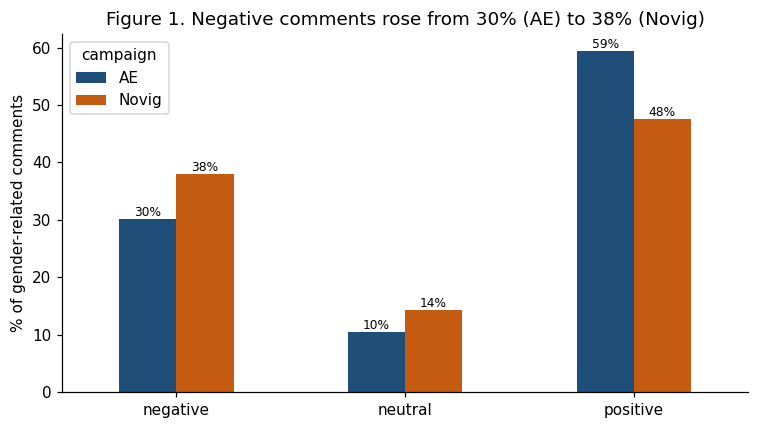

Chi-square = 43.77, df = 2, p = 3.13e-10


In [26]:
# ---- Step 2: share of negative / neutral / positive comments (Figure 1) + chi-square test ----
ORDER = ['negative', 'neutral', 'positive']
# % of each sentiment label within each campaign (normalize='index' = rows add up to 100%)
props = pd.crosstab(sent['campaign'], sent['sentiment'], normalize='index')[ORDER] * 100
display(props.round(1))

# Figure 1: grouped bar chart, AE vs Novig for each sentiment label
ax = props.T.plot(kind='bar', color=[COLORS['AE'], COLORS['Novig']], figsize=(7, 4), rot=0)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.0f%%', fontsize=8)              # write the % on top of each bar
ax.set(ylabel='% of gender-related comments', xlabel='', title='Figure 1. Negative comments rose from 30% (AE) to 38% (Novig)')
plt.tight_layout(); plt.savefig('figures/fig1_sentiment_bar.png', bbox_inches='tight'); plt.show()

# Chi-square test: is the sentiment distribution different between AE and Novig?
chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(sent['campaign'], sent['sentiment']))
print(f"Chi-square = {chi2:.2f}, df = {dof}, p = {p:.3g}")

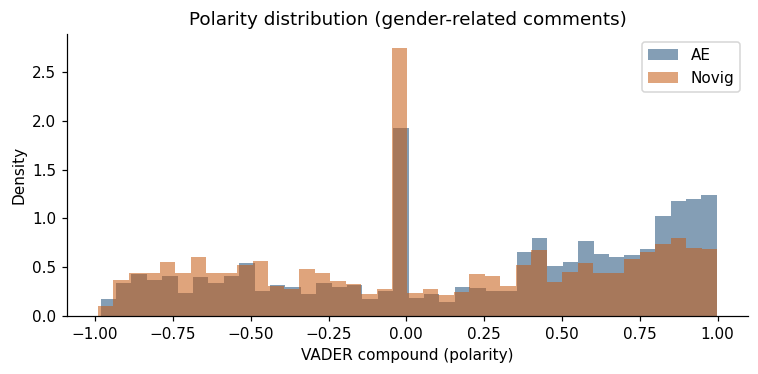

In [27]:
# Optional histogram of polarity (kept in the notebook; not used as a report figure)
fig, ax = plt.subplots(figsize=(7, 3.5))
for camp in ['AE', 'Novig']:
    ax.hist(sent.loc[sent['campaign'] == camp, 'polarity'], bins=40, alpha=0.55,
            color=COLORS[camp], label=camp, density=True)      # density=True: compare shapes despite different sample sizes
ax.set(xlabel='VADER compound (polarity)', ylabel='Density', title='Polarity distribution (gender-related comments)')
ax.legend(); plt.tight_layout(); plt.show()

### 4.2 Intensity, subjectivity and polarisation
- **Intensity** = |polarity|. **Polarisation** = share of comments whose |polarity| reaches the 75th percentile of non-zero scores in the pooled data (zero scores are excluded when setting the threshold, because they are very common).
- Mann–Whitney U tests are used because the scores are not normally distributed; the effect size is the rank-biserial correlation *r*.

In [28]:
def mann_whitney(a, b):
    '''Two-sided Mann-Whitney U test with rank-biserial correlation as effect size.'''
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')   # compares two groups without assuming a normal distribution
    r = 1 - 2 * u / (len(a) * len(b))                           # effect size r: 0 = no difference, ±1 = complete separation
    return u, p, r

sent['intensity'] = sent['polarity'].abs()      # emotional strength regardless of direction (0 = flat, 1 = strongest)
# Polarisation threshold: 75th percentile of |polarity| among non-zero comments (zeros are excluded because there are
# so many of them that the percentile could otherwise be 0); one threshold for both campaigns = the same ruler
threshold = sent.loc[sent['polarity'] != 0, 'intensity'].quantile(0.75)
sent['extreme'] = sent['intensity'] >= threshold    # True = an extreme (strongly positive or strongly negative) comment

rows = []
for metric in ['intensity', 'subjectivity']:
    a = sent.loc[sent['campaign'] == 'AE', metric]; b = sent.loc[sent['campaign'] == 'Novig', metric]
    u, p, r = mann_whitney(a, b)
    rows.append({'metric': metric, 'AE mean': a.mean(), 'Novig mean': b.mean(), 'U': u, 'p': p, 'r (AE vs Novig)': r})
display(pd.DataFrame(rows).round(4))

ext = sent.groupby('campaign')['extreme'].mean() * 100
chi2, p, *_ = stats.chi2_contingency(pd.crosstab(sent['campaign'], sent['extreme']))
print(f"Polarisation threshold |polarity| >= {threshold:.3f}")
print(f"Extreme comments: AE {ext['AE']:.1f}% vs Novig {ext['Novig']:.1f}% "
      f"(difference {ext['Novig'] - ext['AE']:+.1f} pp; chi-square = {chi2:.2f}, p = {p:.3g})")

,metric,AE mean,Novig mean,U,p,r (AE vs Novig)
0,intensity,0.5525,0.4888,1469335.0,0.0000,-0.1205
1,subjectivity,0.4955,0.4672,1372924.5,0.0224,-0.0470


Polarisation threshold |polarity| >= 0.813
Extreme comments: AE 27.2% vs Novig 19.5% (difference -7.6 pp; chi-square = 25.90, p = 3.6e-07)


### 4.3 Does criticism persist within each campaign? (weekly trend)
If audiences became desensitised *within* a campaign, the negative share should fall from the first week to the later weeks. Later weeks have few comments, so they are grouped into three periods with 95% confidence intervals (Figure 2).

n       negative_pct      
campaign   AE Novig           AE Novig
week                                  
1         115   768         30.4  39.1
2         809  1022         29.4  37.4
3         223   139         28.7  41.0
4          62    58         30.6  34.5
5          37    43         43.2  32.6
6          14    31         64.3  25.8
7           7     9         28.6  66.7

mean  size   ci
campaign period                     
AE       Days 1-7    30.4   115  8.4
         Days 8-14   29.4   809  3.1
         Days 15-45  32.1   343  4.9
Novig    Days 1-7    39.1   768  3.5
         Days 8-14   37.4  1022  3.0
         Days 15-45  37.5   280  5.7

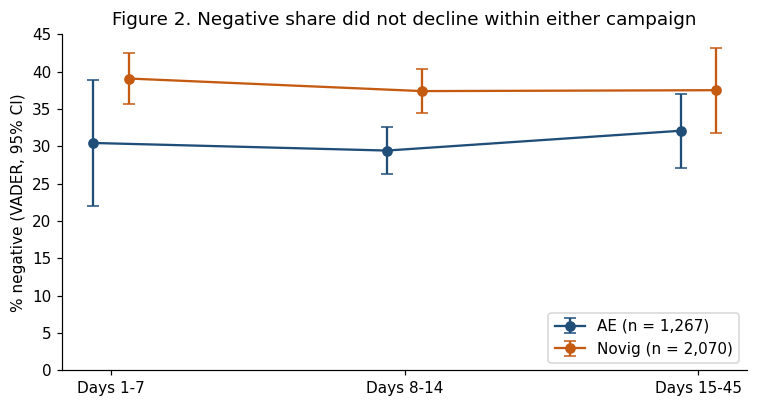

Negative % in first 7 days vs days 8-45:
first_week  False  True 
campaign                
AE           30.2   30.4
Novig        37.4   39.1


In [29]:
# Week number since launch: days 0-6 = week 1, days 7-13 = week 2, ...
sent['week'] = (sent['days_since_launch'] // 7 + 1).clip(upper=7)   # week 7 includes days 42-44
weekly = (sent.assign(negative=sent['sentiment'] == 'negative')     # True/False: is the comment negative?
              .groupby(['campaign', 'week'])
              .agg(n=('negative', 'size'), negative_pct=('negative', 'mean')))   # count and share negative per week
weekly['negative_pct'] *= 100
display(weekly.round(1).unstack(0))

# Later weeks have few comments, so weeks are grouped into three periods and shown with 95% confidence intervals
sent['period'] = pd.cut(sent['days_since_launch'], bins=[-1, 6, 13, 44],
                        labels=['Days 1-7', 'Days 8-14', 'Days 15-45'])
per = (sent.assign(negative=sent['sentiment'] == 'negative')
           .groupby(['campaign', 'period'], observed=True)['negative'].agg(['mean', 'size']))
per['ci'] = 1.96 * np.sqrt(per['mean'] * (1 - per['mean']) / per['size'])   # normal-approximation CI
per[['mean', 'ci']] *= 100
display(per.round(1))

# Figure 2: % negative per period with error bars (overlapping bars = no clear change)
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(3)
for offset, camp in [(-0.06, 'AE'), (0.06, 'Novig')]:  # shift the two lines slightly so error bars do not overlap
    p_ = per.loc[camp]
    ax.errorbar(x + offset, p_['mean'], yerr=p_['ci'], marker='o', capsize=4,
                color=COLORS[camp], label=f"{camp} (n = {p_['size'].sum():,})")
ax.set_xticks(x, ['Days 1-7', 'Days 8-14', 'Days 15-45'])
ax.set(ylim=(0, 45), ylabel='% negative (VADER, 95% CI)',
       title='Figure 2. Negative share did not decline within either campaign')
ax.legend(loc='lower right'); plt.tight_layout()
plt.savefig('figures/fig2_trend.png', bbox_inches='tight'); plt.show()

# Simple check: first week vs the rest
first = sent['days_since_launch'] < 7
print("Negative % in first 7 days vs days 8-45:")
print((sent.assign(first_week=first, negative=sent['sentiment'] == 'negative')
           .groupby(['campaign', 'first_week'])['negative'].mean() * 100).round(1).unstack())

### 4.4 Robustness check 1: do the conclusions hold under TextBlob?
The main results use VADER. If TextBlob, a different dictionary-based tool, shows the same direction of change, the conclusion does not depend on one tool.

In [48]:
# Do VADER and TextBlob rank comments similarly? (Spearman = rank correlation, -1 to +1)
rho, p_rho = stats.spearmanr(sent['polarity'], sent['tb_polarity'])
agree = (sent['sentiment'] == sent['tb_sentiment']).mean()     # share of comments given the same label by both tools
print(f"Spearman correlation VADER vs TextBlob: rho = {rho:.2f} (p = {p_rho:.2g})")
print(f"Label agreement: {agree*100:.1f}%")

# The key question: do both tools show the SAME direction of change from AE to Novig?
robust = pd.DataFrame({
    'VADER % negative': sent.groupby('campaign')['sentiment'].apply(lambda s: (s == 'negative').mean() * 100),
    'TextBlob % negative': sent.groupby('campaign')['tb_sentiment'].apply(lambda s: (s == 'negative').mean() * 100),
    'VADER intensity': sent.groupby('campaign')['polarity'].apply(lambda s: s.abs().mean()),
    'TextBlob intensity': sent.groupby('campaign')['tb_polarity'].apply(lambda s: s.abs().mean()),
}).round(3)
display(robust)
# Repeat the intensity test with TextBlob scores
a = sent.loc[sent['campaign'] == 'AE', 'tb_polarity'].abs(); b = sent.loc[sent['campaign'] == 'Novig', 'tb_polarity'].abs()
u, p, r = mann_whitney(a, b)
print(f"TextBlob intensity Mann-Whitney: p = {p:.3g}, r = {r:.3f}")

Spearman correlation VADER vs TextBlob: rho = 0.54 (p = 2.3e-252)
Label agreement: 64.2%


,VADER % negative,TextBlob % negative,VADER intensity,TextBlob intensity
campaign,,,,
AE,30.229,23.994,0.553,0.234
Novig,38.019,25.121,0.489,0.210


TextBlob intensity Mann-Whitney: p = 4.24e-05, r = -0.084


**Robustness by source type.** The two campaigns have a different source mix (AE: more news; Novig: more creators). If the AE–Novig difference only came from the source mix, it would disappear when comparing the same type of source.

In [49]:
# % negative and mean intensity for each source type x campaign
by_source = (sent.assign(negative=sent['sentiment'] == 'negative')
                 .pivot_table(index='source_type', columns='campaign',
                              values=['negative', 'intensity'], aggfunc='mean'))
by_source[('negative', 'AE')] *= 100; by_source[('negative', 'Novig')] *= 100
n_src = pd.crosstab(sent['source_type'], sent['campaign']).add_prefix('n ')
display(pd.concat([by_source.round(3), n_src], axis=1))

,"(intensity, AE)","(intensity, Novig)","(negative, AE)","(negative, Novig)",n AE,n Novig
source_type,,,,,,
ad,0.555,0.474,27.372,39.120,274,409
commentary,0.488,0.489,26.250,30.909,160,385
creator,0.586,0.490,33.523,40.330,176,667
entertainment,0.501,0.576,32.298,34.177,161,79
news,0.577,0.485,31.250,40.000,496,530


### 4.4b Robustness check 2: a context-aware model (RoBERTa)
VADER and TextBlob score words one by one from a fixed dictionary, so they miss sarcasm and misread emojis (VADER, for example, scores 😂 as clearly positive even when it mocks). `cardiffnlp/twitter-roberta-base-sentiment-latest` is a RoBERTa model trained on about 124 million tweets and fine-tuned for sentiment; it reads the whole sentence, including emojis. It returns probabilities for negative, neutral and positive; *positive − negative* is used as a polarity-like score. It does not measure subjectivity, so it complements rather than replaces the required tools.

*Runs in Colab: Runtime → Change runtime type → T4 GPU (a few minutes); on CPU it is slower but works.*

In [50]:
# ---- Step 1: load RoBERTa and test it on emoji / sarcasm examples ----
import torch
from transformers import pipeline

MODEL = 'cardiffnlp/twitter-roberta-base-sentiment-latest'   # RoBERTa trained on ~124M tweets
device = 0 if torch.cuda.is_available() else -1          # use the GPU if one is available
# top_k=None returns the probability of ALL three labels; truncation cuts very long comments to 256 tokens
roberta = pipeline('sentiment-analysis', model=MODEL, tokenizer=MODEL, top_k=None,
                   truncation=True, max_length=256, device=device)

def prep_for_roberta(text):
    '''Preprocessing recommended on the model card: mask user mentions and links.'''
    words = []
    for w in str(text).split(' '):
        if w.startswith('@') and len(w) > 1:
            w = '@user'
        elif w.startswith('http'):
            w = 'http'
        words.append(w)
    return ' '.join(words)

# Quick check on emoji and sarcasm examples
demo = ["😂😂😂", "🙄", "Wow, so empowering for female athletes 🙄", "Great ad 😍"]
for t, out in zip(demo, roberta(demo)):
    scores = {d['label']: round(d['score'], 2) for d in out}     # {'negative': .., 'neutral': .., 'positive': ..}
    print(f"{t!r:45} RoBERTa {scores} | VADER {vader.polarity_scores(t)['compound']:+.2f}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


'😂😂😂'                                         RoBERTa {'neutral': 0.56, 'positive': 0.28, 'negative': 0.16} | VADER +0.83
'🙄'                                           RoBERTa {'negative': 0.56, 'neutral': 0.37, 'positive': 0.07} | VADER +0.00
'Wow, so empowering for female athletes 🙄'    RoBERTa {'positive': 0.95, 'neutral': 0.04, 'negative': 0.01} | VADER +0.59
'Great ad 😍'                                  RoBERTa {'positive': 0.98, 'neutral': 0.02, 'negative': 0.01} | VADER +0.80


In [51]:
# Score every gender-related comment (batch_size=32: 32 comments at a time, faster)
outputs = roberta(sent['text'].map(prep_for_roberta).tolist(), batch_size=32)
probs = pd.DataFrame([{d['label'].lower(): d['score'] for d in out} for out in outputs], index=sent.index)
sent['rb_polarity'] = probs['positive'] - probs['negative']          # polarity-like score on the same -1 to +1 scale
sent['rb_sentiment'] = probs[['negative', 'neutral', 'positive']].idxmax(axis=1)
sent[['comment_id', 'campaign', 'rb_polarity', 'rb_sentiment']].join(probs).to_csv('roberta_scores.csv', index=False)   # save, so it need not be re-run

# % negative per campaign under each of the three tools
three = pd.DataFrame({
    tool: sent.groupby('campaign')[col].apply(lambda s: (s == 'negative').mean() * 100)
    for tool, col in [('VADER', 'sentiment'), ('TextBlob', 'tb_sentiment'), ('RoBERTa', 'rb_sentiment')]
}).round(1)
print("% negative by tool:"); display(three)
chi2, p, *_ = stats.chi2_contingency(pd.crosstab(sent['campaign'], sent['rb_sentiment']))
print(f"RoBERTa sentiment AE vs Novig: chi-square = {chi2:.2f}, p = {p:.3g}")
print(f"RoBERTa agrees with VADER on {(sent['rb_sentiment'] == sent['sentiment']).mean()*100:.1f}% "
      f"and with TextBlob on {(sent['rb_sentiment'] == sent['tb_sentiment']).mean()*100:.1f}% of comments")

# Where the tools disagree most: VADER says positive, RoBERTa says negative (often sarcasm)
flip = sent[(sent['sentiment'] == 'positive') & (sent['rb_sentiment'] == 'negative')]
print(f"\nVADER positive but RoBERTa negative: {len(flip)} comments ({len(flip)/len(sent)*100:.1f}%). Examples:")
for t in flip['text'].sample(min(8, len(flip)), random_state=SEED):
    print(" -", t[:160].replace('\n', ' '))

% negative by tool:


,VADER,TextBlob,RoBERTa
campaign,,,
AE,30.2,24.0,55.9
Novig,38.0,25.1,65.8


RoBERTa sentiment AE vs Novig: chi-square = 71.91, p = 2.43e-16
RoBERTa agrees with VADER on 53.6% and with TextBlob on 45.1% of comments

VADER positive but RoBERTa negative: 817 comments (24.5%). Examples:
 - She's fine, but media blows up beauty. Every day I come across women much prettier than Sidney. They are just not famous.
 - Idiocracy. She did the ad for a company which used to have woke advertisements. Right wing praised both her and the company right away, ignoring all the past, s
 - Are you really blurring out cleavage? I'm no fan of Sweeny or right wing politics but when I was a kid nudity was a leftist issue. It's utterly insane, we are m
 - okay this has absolutely nothing to do with sports they should've taken woman from different sports and given them this
 - I love the way they suggest this it strike two for Sydney, strike one ging the jeans commercial. As if this publication will have even the slightest bearing on 
 - American Eagle has the whole world talking about 

**Result.** 
RoBERTa labels far more comments as negative than the dictionary tools (AE 55.9%, Novig 65.8%) and agrees with VADER on only 53.6% of comments; 24.5% of comments are positive for VADER but negative for RoBERTa. The examples mix criticism of the ad with attacks on the critics, often in polite or ironic wording. Despite the different levels, the direction is the same as VADER: the negative share rises from AE to Novig (+9.9 percentage points, χ² = 71.91, p < .001). The rise in negative tone therefore does not depend on the tool, although its size does (VADER +7.8, TextBlob +1.1, RoBERTa +9.9 points). RoBERTa reads emojis better than VADER (😂😂😂 neutral and 🙄 negative, where VADER gives +0.83 and 0.00), but it still scores the sarcastic test sentence as positive (0.95).

### 4.5 Topic modelling (LDA)
One LDA model is fitted on the **pooled** gender-related comments of both campaigns, so that both campaigns share the same topics and their topic shares can be compared directly. Only comments with at least 3 tokens are used.

*Note: pyLDAvis numbers topics from 1, while Table 1 numbers them from 0 (Topic 1 in the map = Topic 0 in Table 1). The order is the same because `sort_topics=False`.*

In [34]:
# One topic model on the POOLED gender subset, so both campaigns share the same topics and can be compared
lda_df = sent[sent['tokens'].str.len() >= 3].reset_index(drop=True)   # very short comments carry too little topic information
texts = lda_df['tokens'].tolist()
dictionary = corpora.Dictionary(texts)
dictionary.filter_extremes(no_below=5, no_above=0.5)      # drop very rare and very common words
corpus = [dictionary.doc2bow(t) for t in texts]
print(f"Documents: {len(texts)}, vocabulary: {len(dictionary)}")

models, scores = {}, {}
for k in [3, 4, 5]:                                       # the guideline asks for 3-5 topics
    # passes=15 = 15 rounds over the data; random_state fixes the result; alpha='auto' learns topic mix from the data
    m = LdaModel(corpus, num_topics=k, id2word=dictionary, passes=15, random_state=SEED, alpha='auto')
    # c_v coherence: do the top words of each topic tend to appear together? Higher = more interpretable
    cm = CoherenceModel(model=m, texts=texts, dictionary=dictionary, coherence='c_v', processes=1)
    models[k], scores[k] = m, cm.get_coherence()
    print(f"k = {k}: coherence c_v = {scores[k]:.3f}")

best_k = max(scores, key=scores.get)
lda = models[best_k]
print("Selected k =", best_k)

Documents: 3220, vocabulary: 1618
k = 3: coherence c_v = 0.417
k = 4: coherence c_v = 0.443
k = 5: coherence c_v = 0.429
Selected k = 4


In [35]:
# Top 10 words of each topic, with their weights
for tid, words in lda.print_topics(num_words=10):
    print(f"Topic {tid}: {words}\n")

Topic 0: 0.044*"girl" + 0.028*"white" + 0.025*"jean" + 0.020*"beautiful" + 0.018*"people" + 0.017*"gene" + 0.017*"black" + 0.014*"great" + 0.013*"blue" + 0.012*"jealous"

Topic 1: 0.017*"body" + 0.017*"sport" + 0.013*"men" + 0.012*"people" + 0.011*"company" + 0.010*"sex" + 0.008*"many" + 0.007*"sell" + 0.007*"marketing" + 0.006*"less"

Topic 2: 0.021*"people" + 0.016*"beautiful" + 0.014*"body" + 0.012*"shes" + 0.011*"jean" + 0.010*"men" + 0.008*"good" + 0.008*"something" + 0.007*"girl" + 0.007*"doe"

Topic 3: 0.062*"sport" + 0.035*"men" + 0.032*"athlete" + 0.030*"female" + 0.018*"body" + 0.013*"womens" + 0.009*"people" + 0.009*"gambling" + 0.008*"betting" + 0.007*"nothing"



In [36]:
# Interactive topic map (saved as HTML; open it in a browser)
import pyLDAvis, pyLDAvis.gensim_models
# mds='mmds' = the layout method for the map (the default one fails on this data with a JSON error)
vis = pyLDAvis.gensim_models.prepare(lda, corpus, dictionary, sort_topics=False, mds='mmds')
pyLDAvis.save_html(vis, 'figures/lda_topics.html')
print("Saved figures/lda_topics.html")

Saved figures/lda_topics.html


In [37]:
# Assign each comment its dominant topic
def dominant_topic(bow):
    topics = lda.get_document_topics(bow, minimum_probability=0)
    return max(topics, key=lambda x: x[1])

dom = [dominant_topic(b) for b in corpus]
lda_df['topic'] = [t for t, _ in dom]
lda_df['topic_prob'] = [p for _, p in dom]

# Representative comments: highest topic probability (read these to name the topics)
for t in range(best_k):
    print(f"===== Topic {t} =====")
    for txt in lda_df[lda_df['topic'] == t].nlargest(5, 'topic_prob')['text']:
        print(" -", txt[:200].replace('\n', ' '))
    print()

===== Topic 0 =====
 - Bro these people need to represent america in olympic long jump. Because the leap and filler to go from the words in the ad to something that makes it about white supremacy is fucking impressively rac
 - Of course, the right wing people are going to say that this is left people attacking a beautiful woman… funny cuz it’s not even about attractiveness can we step away from that for a second.. I know th
 - So this is the ad everyone is talking about... it's literally a comparison to her gene eye color and the jean color being blue, and then the male voice over saying Sydney has great jeans. Bruh, no one
 - I'm a South Asian girl and I also agree Caucasian women AND Men are beautiful. I've never thought of Sidney as the prettiest girl out there but she definitely looks attractive because of her skin, hai
 - Pathetic pathetic people.   How DARE a white woman make a pun about her great genetic makeup! Must be a n*zi.  If any other race was featured in this ad, or even

In [38]:
# ---- Name the topics and build Table 1 (share and sentiment of each topic, by campaign) ----
TOPIC_NAMES = {   # named after reading the top words AND the representative comments above
    0: 'Race, genes and beauty',
    1: 'Sex sells and the feminism debate',
    2: 'Praise and defence of Sweeney',
    3: "Women's sport and athletes",
}

topic_share = pd.crosstab(lda_df['topic'], lda_df['campaign'], normalize='columns') * 100
topic_pol = lda_df.pivot_table(index='topic', columns='campaign', values='polarity', aggfunc='mean')
topic_neg = lda_df.assign(neg=lda_df['sentiment'] == 'negative').pivot_table(
    index='topic', columns='campaign', values='neg', aggfunc='mean') * 100
top_words_t = {t: ', '.join(w for w, _ in lda.show_topic(t, topn=8)) for t in range(best_k)}

# Table 1 for the report: topics x campaign, combining share and sentiment (does sentiment match topic?)
table1 = pd.DataFrame({
    'Topic': [TOPIC_NAMES.get(t, f'Topic {t}') for t in range(best_k)],
    'Top words': [top_words_t[t] for t in range(best_k)],
    'AE share (%)': topic_share['AE'].round(1).values,
    'Novig share (%)': topic_share['Novig'].round(1).values,
    'AE mean polarity': topic_pol['AE'].round(3).values,
    'Novig mean polarity': topic_pol['Novig'].round(3).values,
    'AE % negative': topic_neg['AE'].round(1).values,
    'Novig % negative': topic_neg['Novig'].round(1).values,
})
table1.to_csv('figures/table1_topics.csv', index=False)
table1

,Topic,Top words,AE share (%),Novig share (%),AE mean polarity,Novig mean polarity,AE % negative,Novig % negative
0,"Race, genes and beauty","girl, white, jean, beautiful, people, gene, black, great",60.8,19.2,0.221,0.071,32.5,41.4
1,Sex sells and the feminism debate,"body, sport, men, people, company, sex, many, sell",5.2,13.1,0.083,0.064,39.1,41.4
2,Praise and defence of Sweeney,"people, beautiful, body, shes, jean, men, good, something",26.1,18.7,0.305,0.161,24.7,34.4
3,Women's sport and athletes,"sport, men, athlete, female, body, womens, people, gambling",7.9,49.0,0.112,0.056,32.0,39.0


### 4.6 AE over ~15 months (extension of RQ1)
All AE comments (every AE video, no sampling) are grouped into four phases, because per-month counts become small after the first two months. The same indicators are computed for every phase.

In [39]:
# Four phases of the AE campaign's life: (name, start date, end date)
PHASES = [('1 Launch', '2025-07-23', '2025-09-01'),
          ('2 Cooling', '2025-09-01', '2026-01-01'),
          ('3 Long tail', '2026-01-01', '2026-09-09'),
          ('4 After Novig', '2026-09-09', '2027-01-01')]

def assign_phase(ts):
    # Return the name of the phase that contains timestamp ts
    for name, start, end in PHASES:
        if pd.Timestamp(start, tz='UTC') <= ts < pd.Timestamp(end, tz='UTC'):
            return name
    return None

ae = ae_long.copy()
ae['phase'] = ae['published_at'].apply(assign_phase)
ae['clean_text'] = ae['text'].apply(clean_text)
ae = ae[ae['clean_text'].str.len() > 0]
# Language filter on the later phases only (the launch phase is very large and almost all English)
late = ae['phase'] != '1 Launch'
ae = pd.concat([ae[~late], ae[late][ae[late]['text'].apply(is_english)]])
ae['polarity'] = ae['text'].apply(lambda t: vader.polarity_scores(t)['compound'])   # VADER, as in the main analysis
ae['gender_related'] = ae['clean_text'].str.contains(GENDER_RE)
ae['outrage'] = ae['text'].str.lower().str.contains(compile_lexicon(OUTRAGE))
ae['tactic'] = ae['text'].str.lower().str.contains(compile_lexicon(TACTIC))

# One row per phase
phase_table = ae.groupby('phase').agg(
    comments=('text', 'size'),
    gender_related=('gender_related', 'sum'),
    negative_pct=('polarity', lambda s: (s < -0.05).mean() * 100),   # same -0.05 cut-off as label_sentiment
    intensity=('polarity', lambda s: s.abs().mean()),
    outrage_pct=('outrage', lambda s: s.mean() * 100),
    tactic_pct=('tactic', lambda s: s.mean() * 100),
).round(2)
phase_table

,comments,gender_related,negative_pct,intensity,outrage_pct,tactic_pct
phase,,,,,,
1 Launch,55464,6624,31.61,0.45,1.81,2.64
2 Cooling,3086,291,32.60,0.44,2.43,1.91
3 Long tail,1307,110,31.22,0.45,1.91,1.76
4 After Novig,333,29,28.53,0.41,2.70,2.40


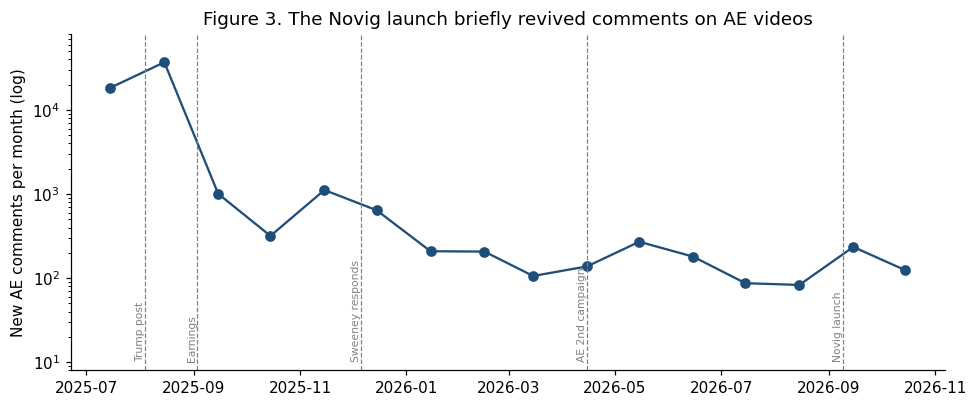

In [40]:
# Monthly volume with key events (log scale because the launch months dominate).
# Note: July 2025 starts on the 23rd and the last month is incomplete.
monthly = ae.set_index('published_at').resample('MS').size()
EVENTS = {'Trump post': '2025-08-04', 'Earnings': '2025-09-03', 'Sweeney responds': '2025-12-06',
          'AE 2nd campaign': '2026-04-15', 'Novig launch': '2026-09-09'}
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(monthly.index + pd.Timedelta(days=14), monthly.values, marker='o', color=COLORS['AE'])  # plot at mid-month
ax.set_yscale('log'); ax.set_ylim(8, 8e4)            # log scale: 10, 100, 1,000 ... are equally spaced
for label, d in EVENTS.items():
    x = pd.Timestamp(d, tz='UTC'); ax.axvline(x, color='grey', ls='--', lw=0.8)
    ax.text(x, 10, label, rotation=90, va='bottom', ha='right', fontsize=7, color='grey')
ax.set(ylabel='New AE comments per month (log)', title='Figure 3. The Novig launch briefly revived comments on AE videos')
plt.tight_layout(); plt.savefig('figures/fig3_ae_longitudinal.png', bbox_inches='tight'); plt.show()

In [41]:
# Spillover: did the Novig launch send people back to the AE videos?
novig_launch = pd.Timestamp('2026-09-09', tz='UTC')
# AE comments in the 30 days before and the 30 days after the Novig launch
before = ae[(ae['published_at'] >= novig_launch - pd.Timedelta(days=30)) & (ae['published_at'] < novig_launch)]
after = ae[(ae['published_at'] >= novig_launch) & (ae['published_at'] < novig_launch + pd.Timedelta(days=30))]
# Word boundaries (\b) matter: without them 'against' would be counted as 'again'
REF_RE = re.compile(r'\b(?:novig|sports?|again|naked|nude|betting)\b')
window = pd.concat([before.assign(after=False), after.assign(after=True)])
window['refers_to_novig'] = window['text'].str.lower().str.contains(REF_RE)
window['negative'] = window['polarity'] < -0.05

n_before, n_after = len(before), len(after)
print(f"AE comments 30 days before Novig launch: {n_before} | 30 days after: {n_after} (x{n_after/max(n_before,1):.1f})")
# Volume: if the launch made no difference, each comment would be equally likely to fall before or after (p = 0.5)
print(f"  Binomial test on volume: p = {stats.binomtest(n_after, n_before + n_after, 0.5).pvalue:.2g}")

summary_spill = window.groupby('after').agg(
    comments=('text', 'size'),
    refers_pct=('refers_to_novig', lambda s: s.mean() * 100),
    negative_pct=('negative', lambda s: s.mean() * 100),
    intensity=('polarity', lambda s: s.abs().mean()),
).round(2)
summary_spill.index = ['30 days before', '30 days after']
display(summary_spill)

# Fisher's exact test is used for references because one cell is 0 (chi-square is unreliable with tiny counts)
_, p_ref = stats.fisher_exact(pd.crosstab(window['after'], window['refers_to_novig']).values)
_, p_neg, *_ = stats.chi2_contingency(pd.crosstab(window['after'], window['negative']))
_, p_int = stats.mannwhitneyu(before['polarity'].abs(), after['polarity'].abs())
print(f"Referring to the Novig ad: Fisher's exact p = {p_ref:.3f}")
print(f"Negative share: chi-square p = {p_neg:.3f} | Intensity: Mann-Whitney p = {p_int:.3f}")
print("Small samples: treat these tests as supporting evidence, not the main result.\n")

# Print every matching comment so the keyword matches can be checked by reading
refs = window[window['after'] & window['refers_to_novig']]
print(f"Comments after launch matching the keywords ({len(refs)}). Read them all: some match by coincidence.")
for t in refs['text']:
    print(" -", t[:160].replace('\n', ' '))

AE comments 30 days before Novig launch: 80 | 30 days after: 265 (x3.3)
  Binomial test on volume: p = 2.8e-24


,comments,refers_pct,negative_pct,intensity
30 days before,80,0.00,22.50,0.40
30 days after,265,9.06,29.81,0.43


Referring to the Novig ad: Fisher's exact p = 0.002
Negative share: chi-square p = 0.257 | Intensity: Mann-Whitney p = 0.499
Small samples: treat these tests as supporting evidence, not the main result.

Comments after launch matching the keywords (24). Read them all: some match by coincidence.
 - Everyone defending her just wait for the sports ad lmao
 - Who is here after the sports ad?
 - She has done it again on Novig!
 - Ofc I get recommended this after the sports ad
 - I think I know sports
 - Idk why I’ve came back to see this again but I don’t think it was racist?
 - This is better than sports ad tho
 - tbh though (not trying to defend sydney esp after her new sports ad) saying she has great genes is not putting other women down idk why people were so hung up o
 - At least this is better than the sports add
 - Here after people got mad at her again for saying the same thing in the new ad
 - Should remake this video w the sports one 😂😂
 - Me watching this in 2026 after her sports

**Exploratory reading: the target of criticism moves.** All keyword-matching AE comments posted after the Novig launch were read and sorted by hand. Of the comments that evaluate the ads, some judge the AE ad as comparatively harmless (*"This is better than sports ad tho"*), while others frame Novig as an escalation of the same tactic (*"She has done it again on Novig!"*). Both groups see Novig as worse. This is consistent with a **contrast effect** in Social Judgment Theory (Sherif & Hovland, 1961): a more extreme stimulus becomes the new anchor, so the earlier one looks milder. Because the sample is small and self-selected, this is reported as an exploratory pattern, not a measured proportion.

### 4.7 Stance, target and response mode (sentiment ≠ stance)
The research question concerns **criticism**, an evaluative position, not tone. In this corpus the two often diverge: sarcastic critics use positive wording, while defenders attack the critics in negative language. A random sample of 200 gender-related comments per campaign was therefore coded on three dimensions:

| Dimension | Categories |
|---|---|
| **Stance** toward the ad's portrayal of Sweeney's body and appearance (including the AE "great genes" racial reading) | *accepting* (treats the portrayal as unproblematic: praising her looks, defending her choice, denying the critique, attacking critics) · *objecting* (treats it as problematic) · *neutral* (no position; remarks only about her acting or character; gambling only; unrelated) |
| **Target**: whom the comment mainly evaluates | the ad, brand or controversy · Sweeney herself · the critics / other commenters · other |
| **Response mode** (links to Framework T) | moral criticism (T1) · tactic recognition (T3) · indifference (T2) · praise or defence · other |

Labels were pre-assigned with AI assistance and then reviewed one by one by the author (stance_labels.csv; the label_source column records this).

In [42]:
# Random sample: 200 gender-related comments per campaign (equal size, so percentages are comparable)
stance_sample = sent.groupby('campaign').sample(n=200, random_state=SEED)
keep = ['comment_id', 'campaign', 'source_type', 'text', 'polarity', 'sentiment', 'tb_polarity', 'tb_sentiment']
keep += [c for c in ['rb_polarity', 'rb_sentiment'] if c in stance_sample.columns]   # RoBERTa, if it was run
stance_sample[keep].to_csv('stance_sample.csv', index=False)     # this file was coded (AI pre-label + author review)
print("Exported", len(stance_sample), "comments to stance_sample.csv")

Exported 400 comments to stance_sample.csv


In [45]:
# ---- Load the reviewed labels and compare AE vs Novig on stance, target and response mode ----
labels = pd.read_csv('stance_labels.csv')                 # one row per sampled comment
# Join the labels to the sample by comment_id (campaign is dropped from labels because the sample already has it)
coded = stance_sample.merge(labels.drop(columns='campaign'), on='comment_id')
print("Coded comments:", len(coded), "| label source:", ', '.join(coded['label_source'].unique()))

def compare(col):
    '''Percentage table by campaign plus a chi-square test.'''
    pct = pd.crosstab(coded['campaign'], coded[col], normalize='index').mul(100).round(1)
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(coded['campaign'], coded[col]))
    print(f"\n{col}: chi-square = {chi2:.2f}, df = {dof}, p = {p:.3g}"); display(pct)

for col in ['stance', 'target', 'response_mode']:
    compare(col)

def two_by_two(mask, label):
    '''Fisher's exact test for one category (AE vs Novig).'''
    # mask = True/False for one category; Fisher's exact test suits the small counts here
    _, p = stats.fisher_exact(pd.crosstab(coded['campaign'], mask).values)
    share = mask.groupby(coded['campaign']).mean() * 100
    print(f"{label}: AE {share['AE']:.1f}% vs Novig {share['Novig']:.1f}% (Fisher p = {p:.3f})")

print()
two_by_two(coded['stance'] == 'objecting', 'Objecting')
for m in ['moral_criticism', 'tactic_recognition', 'indifference']:   # T1, T3 and T2 response modes
    two_by_two(coded['response_mode'] == m, m)

# Whom are the objecting comments aimed at? (Comments only about her acting or character are already coded neutral,
# so objecting comments about Sweeney herself concern her body and appearance, i.e. the portrayal itself.)
obj = coded[coded['stance'] == 'objecting']
print("\nObjecting comments by target (counts):")
display(pd.crosstab(obj['target'], obj['campaign'], margins=True))

# Which targets differ between campaigns? (Fisher's exact test per category)
for t in ['critics_commenters', 'ad_brand_controversy', 'sweeney_herself']:
    two_by_two(coded['target'] == t, f"Target = {t}")

Coded comments: 400 | label source: AI pre-label, reviewed by author

stance: chi-square = 8.28, df = 2, p = 0.0159


stance,accepting,neutral,objecting
campaign,,,
AE,68.0,25.0,7.0
Novig,68.5,17.0,14.5



target: chi-square = 20.08, df = 3, p = 0.000164


target,ad_brand_controversy,critics_commenters,other,sweeney_herself
campaign,,,,
AE,33.0,34.5,11.0,21.5
Novig,24.0,56.5,6.0,13.5



response_mode: chi-square = 13.38, df = 4, p = 0.00957


response_mode,indifference,moral_criticism,other,praise_defence,tactic_recognition
campaign,,,,,
AE,4.0,6.0,21.0,64.0,5.0
Novig,1.0,13.0,14.0,63.5,8.5



Objecting: AE 7.0% vs Novig 14.5% (Fisher p = 0.023)
moral_criticism: AE 6.0% vs Novig 13.0% (Fisher p = 0.026)
tactic_recognition: AE 5.0% vs Novig 8.5% (Fisher p = 0.231)
indifference: AE 4.0% vs Novig 1.0% (Fisher p = 0.105)

Objecting comments by target (counts):


campaign,AE,Novig,All
target,,,
ad_brand_controversy,9,19,28
critics_commenters,1,2,3
sweeney_herself,4,8,12
All,14,29,43


Target = critics_commenters: AE 34.5% vs Novig 56.5% (Fisher p = 0.000)
Target = ad_brand_controversy: AE 33.0% vs Novig 24.0% (Fisher p = 0.059)
Target = sweeney_herself: AE 21.5% vs Novig 13.5% (Fisher p = 0.048)


**How well does sentiment stand in for criticism?** Each tool's *negative* label is compared with the *objecting* stance. This is not a sentiment-accuracy score; it shows how far tone can be read as criticism.

In [46]:
# ---- How well does each sentiment tool capture criticism (objecting stance)? ----
tools = [('VADER', 'sentiment'), ('TextBlob', 'tb_sentiment')]
if 'rb_sentiment' in coded.columns:                  # add RoBERTa only if section 4.4b was run
    tools.append(('RoBERTa', 'rb_sentiment'))

rows = []
for tool, col in tools:
    neg, obj = coded[col] == 'negative', coded['stance'] == 'objecting'
    rows.append({'tool': tool,
                 '% of objecting comments scored negative': neg[obj].mean() * 100,          # how much criticism the tool catches
                 '% of negative comments that object': obj[neg].mean() * 100,              # how much of 'negative' is real criticism
                 '% of negative comments that ACCEPT': (coded.loc[neg, 'stance'] == 'accepting').mean() * 100,   # e.g. defenders attacking critics
                 'objecting comments scored positive': int((obj & (coded[col] == 'positive')).sum())})          # e.g. sarcasm
display(pd.DataFrame(rows).round(1))

# Where does the rise in negative tone come from? Negative comments split by stance
neg = coded[coded['sentiment'] == 'negative']
# Divide by the campaign's sample size (200) so the numbers are % of ALL sampled comments
split = pd.crosstab(neg['campaign'], neg['stance']).div(coded['campaign'].value_counts(), axis=0).mul(100).round(1)
print("VADER-negative comments as % of all sampled comments, split by stance:"); display(split)
print("Targets of VADER-negative comments:"); display(pd.crosstab(neg['campaign'], neg['target']))

,tool,% of objecting comments scored negative,% of negative comments that object,% of negative comments that ACCEPT,objecting comments scored positive
0,VADER,46.5,16.3,64.2,20
1,TextBlob,32.6,15.6,62.2,24
2,RoBERTa,74.4,13.0,67.2,5


VADER-negative comments as % of all sampled comments, split by stance:


stance,accepting,neutral,objecting
campaign,,,
AE,15.0,5.0,2.0
Novig,24.5,7.0,8.0


Targets of VADER-negative comments:


target,ad_brand_controversy,critics_commenters,other,sweeney_herself
campaign,,,,
AE,13,21,3,7
Novig,17,46,7,9


**Result.** RoBERTa catches the most objecting comments (74.4% scored negative, vs 46.5% for VADER and 32.6% for TextBlob) and rarely scores them positive (5 comments, vs 20 and 24). But only 13.0% of its negative comments actually object, while 67.2% accept the portrayal. Combining both (F1 of "negative" as a detector of "objecting"), all three tools are weak and close: VADER 0.24, RoBERTa 0.22, TextBlob 0.21. Following the rule set in advance (the tool that best matches the stance labels is the primary tool), VADER remains the primary tool. None of the tools can stand in for stance coding: they measure tone, not position.

**Stance classifier.** Can a simple model learn stance from these labels and extend it to all gender-related comments? TF–IDF + Logistic Regression (balanced class weights), 5-fold cross-validation. Rule set in advance: extend only if macro-F1 ≥ 0.70.

In [47]:
# ---- Stance classifier: can a model learn the human labels? (decides whether labels can be extended) ----
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, classification_report

# 5-fold cross-validation: train on 4/5 of the labels, predict the other 1/5, repeat 5 times.
# Stratified = each fold keeps the same mix of stances, so every comment is predicted by a model that never saw it.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
# Pipeline: text -> TF-IDF features -> logistic regression; class_weight='balanced' gives the rare objecting class more weight
clf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                    LogisticRegression(max_iter=2000, class_weight='balanced'))
X_text, y_stance = coded['text'].astype(str), coded['stance']

pred = cross_val_predict(clf, X_text, y_stance, cv=cv)
# Macro-F1 = average F1 of the three classes (treats the rare class as equally important). Pre-set rule: extend only if >= 0.70
print(f"3-class macro-F1 = {f1_score(y_stance, pred, average='macro'):.3f}")
print(classification_report(y_stance, pred, digits=2))

y_obj = y_stance == 'objecting'                          # fallback: objecting vs everything else
pred_b = cross_val_predict(clf, X_text, y_obj, cv=cv)
print(f"Binary (objecting vs not) macro-F1 = {f1_score(y_obj, pred_b, average='macro'):.3f}; "
      f"F1 for the objecting class alone = {f1_score(y_obj, pred_b):.3f}")

3-class macro-F1 = 0.475
              precision    recall  f1-score   support

   accepting       0.76      0.81      0.78       273
     neutral       0.33      0.27      0.30        84
   objecting       0.36      0.33      0.34        43

    accuracy                           0.65       400
   macro avg       0.48      0.47      0.47       400
weighted avg       0.63      0.65      0.63       400

Binary (objecting vs not) macro-F1 = 0.643; F1 for the objecting class alone = 0.348


### 4.8 Reflection

*Stance, target and response-mode labels were AI pre-labelled and reviewed one by one by the author, who changed 6.8% of stance, 27.3% of target and 10.5% of response-mode labels.*

**Do sentiment and topic patterns align?** Topic shares differ far more between the campaigns than within-topic sentiment does. *Women's sport and athletes* rises from 7.9% to 49.0% of gender comments and *Sex sells and the feminism debate* from 5.2% to 13.1%. At the same time, the negative share is higher for Novig **in every topic** (VADER: 24.7–39.1% for AE vs 34.4–41.4% for Novig). The discussion moved to a new subject *and* became more critical.

**Are discussions positive, critical or polarised?** Most gender comments are still positive (VADER: 59.4% AE, 47.6% Novig), largely because defenders praise Sweeney's looks, but the negative share rises from 30.2% to 38.0% (p < .001). Extreme comments become **less** common (27.2% → 19.5%, p < .001) and emotional intensity falls slightly (0.553 → 0.489, r = −0.12). Criticism became more widespread but less extreme.

**What does this mean for Framework T?**
- Criticism did **not** fade: the negative share rose, Figure 2 shows no decline within either 45-day window, and moral-outrage vocabulary tripled (4.1% → 13.4%). This is **not** consistent with desensitisation (T2).
- The rise holds in all five source types, so it is not an artefact of Novig's different source mix.
- Lower intensity, fewer extreme comments and more tactic-recognition vocabulary (3.8% → 5.7%) suggest criticism became **more measured and more aware of the tactic**, but no less present: closest to *"recognised the tactic, but still critical"*, i.e. persistence (T1) with an element of persuasion knowledge (T3).
- The direction holds across tools, but the size does not: the negative share rises by 7.8 points with VADER, 9.9 with RoBERTa (55.9% → 65.8%, p < .001) and only 1.1 with TextBlob (24.0% → 25.1%). TextBlob also shows lower intensity for Novig.
- **Stance settles this (Part 4.7).** In the coded sample, comments *objecting* to the portrayal double (7.0% → 14.5%, p = .023). The rise appears both in objections aimed at the ad or brand (9 → 19 comments) and in those aimed at Sweeney herself (4 → 8), who in the Novig case is also an equity partner in the brand. Criticism did not fade.
- **Negative tone is not criticism.** About two thirds of negative comments in the sample *accept* the portrayal (VADER 64%, RoBERTa 67%): they are defenders attacking the critics, and only 47% of objecting comments are scored negative at all. Most of the rise in negative tone comes from these defenders (15.0% → 24.5% of sampled comments, versus 2.0% → 8.0% for objecting comments). Comments aimed at the critics rise from 34.5% to 56.5% (p < .001), while comments about the ad, brand or controversy fall from 33.0% to 24.0% (p = .06, not significant). The Novig debate became largely a fight **about the critics**.
- **Response modes** shift in the T1/T3 direction (overall p = .010): moral criticism doubles (6.0% → 13.0%, p = .026), tactic recognition rises (5.0% → 8.5%, n.s.) and indifference falls (4.0% → 1.0%, n.s.). There is no sign of growing indifference (T2).
- A TF–IDF classifier reaches a 3-class macro-F1 of only 0.48 (binary objecting vs not: 0.64; objecting class alone: 0.35), so stance is not extended to the full corpus: recognising stance requires context that word counts miss.
- On AE's own timeline the negative share stays around 31–33% until the debate fades and is 28.5% after Novig's launch; the Novig launch sent people back to the AE videos (×3.3 comments), some of whom now judged the AE ad as *"better than the sports ad"*. The second controversy appears to have moved the reference point for the first.

**Implications.**
- *Advertising regulators*: the Novig debate centred on a gambling product using a sexualised image in a sports context, where existing gambling-advertising rules on appeal and audience are most relevant.
- *Women's sport organisations*: athletes' criticism set the agenda for the Novig discussion (half of gender comments), showing their voice can shape public framing.
- *Platform moderators*: both comment sections contain insults aimed at women and at critics, concentrated in the most polarised threads.
- *Brands*: criticism did not wear off with repetition, yet both brands reported commercial gains; outrage functions as an attention resource, which raises ethical rather than only strategic questions.